# Normalisation and averaging of perdiodic viscoelastic properties in for sarcomere 

This notebook  normalising the sacromere length to the peak to peak distance on of the Z disc from the E0 and averages over all the sarcomeres mechanically mapped viscoelasticity using Atomic force microscopy mapping. 

### Methodology
- Localised peak finding to identify the stiff z-discs of a sarcomere
- Normalise the the pk-pk distance as the sarcomere length
- Compute average Viscoelastivity line profiles over all the sarcomeres probed over the normalised distance.

### Inputs
- Line profiles of E0 and beta for each sarcomere as a CSV file.

### Outputs
- Averaged l E0 and beta values as a function of normalized z-disc to z-disc length 

In [1]:
#Import required modules
import pandas as pd
from scipy.signal import find_peaks
import numpy as np 
import matplotlib.pyplot as plt

#from utils import do_LP_colred_SEM # Function to average local L_p over time for a given configuration
from utils import find_glob_peak
from utils import randomize_sacs

import warnings
warnings.filterwarnings("ignore")  # Suppress non-critical warnings


## Loading the data and configuring the analysis

In [2]:
df_mech = pd.read_csv('data/example_data.csv')


# window size for averaging the line profiles of E0 and beta  
window_size = 1 # in percentage of normalized sarcomere lenght
# for the larval data, 20 percent is a good value, and for IFM data 1 percent was used in the article  


#Guess peak height and distance for the find_peaks function
height = 1
distance = 5


## Prepping the data

In [3]:
for name, df in df_mech.groupby('file_sarc'):
    mask = (df_mech['file_sarc'] == name)

    sac_len = df["distance"].max()
    df_mech.loc[mask, 'sarc_len'] = sac_len
    df_mech.loc[mask, 'norm_dist'] = df["distance"] / sac_len
    df_mech.loc[mask, 'pk_1_pos'] = 0.09 #guess posistion of peak 1
    df_mech.loc[mask, 'pk_2_pos'] = 0.94 #guess posistion of peak 2

## Finding peaks around the guess peak positions

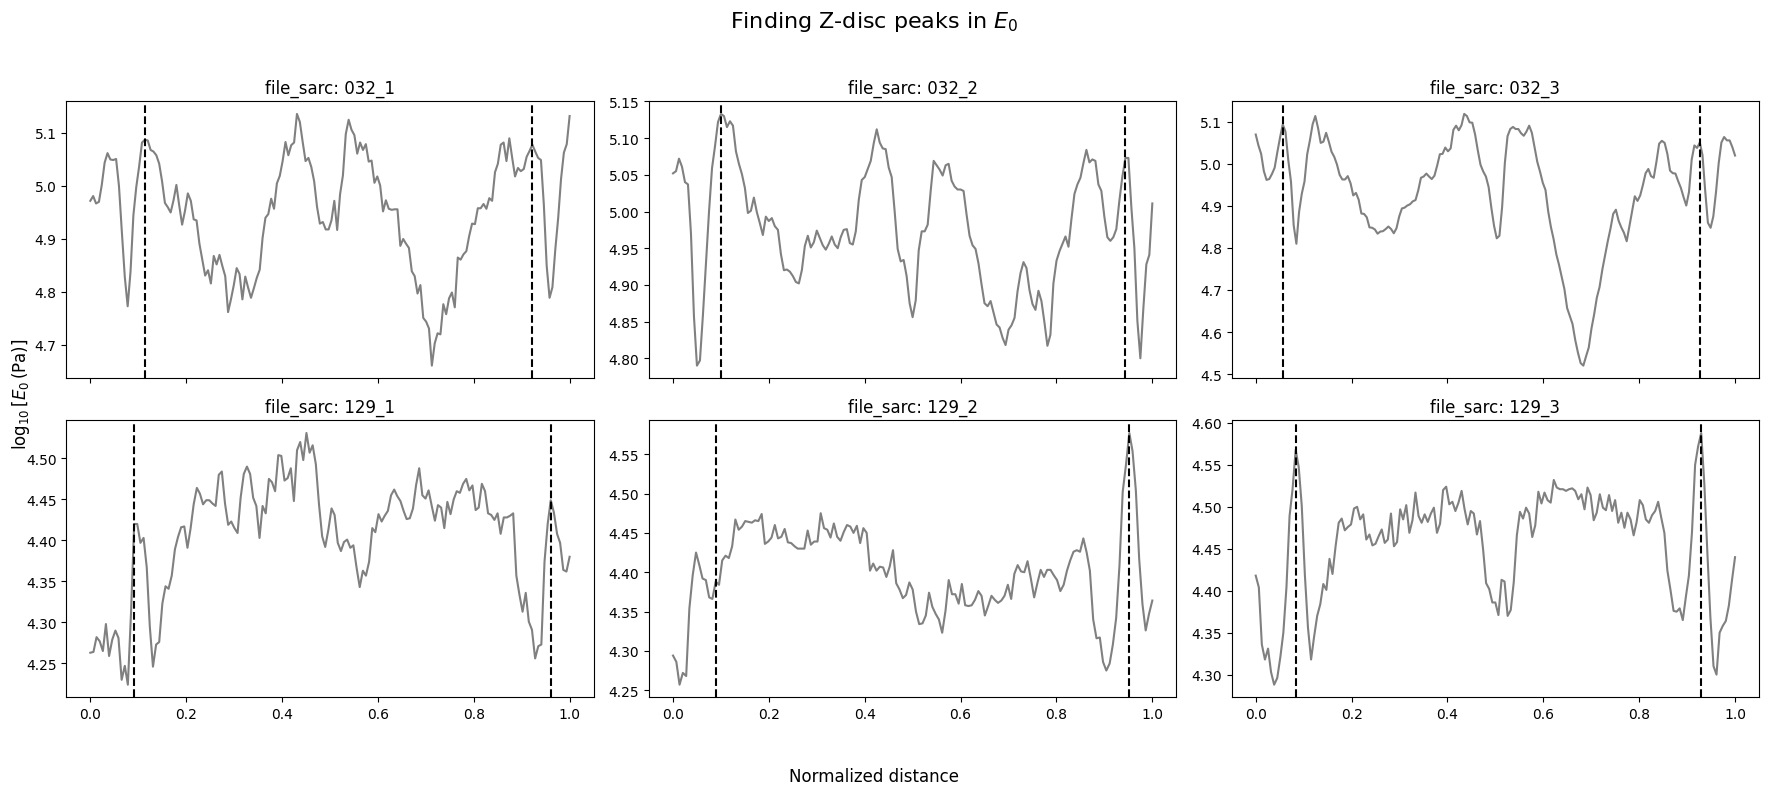

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 8), sharex=True)
axes_lin = axes.flatten()
for ax, (name, df) in zip(axes_lin, df_mech.groupby('file_sarc')):

    mask = (df_mech['file_sarc'] == name)

    high_peak_guess = [df['pk_1_pos'].iloc[0], df['pk_2_pos'].iloc[0]]

    peaks, _ = find_peaks(df['E_0'], height=height, distance=distance)

    temp_arr = df['norm_dist'].iloc[peaks].to_numpy()

    peak_pos = find_glob_peak(temp_arr, high_peak_guess)

    if -1 in peak_pos:
        peak_pos[peak_pos == -1] = -np.where(peak_pos == -1)[0]

    pk1, pk2 = peaks[int(peak_pos[0])], peaks[int(peak_pos[1])]
    
    df_mech.loc[mask, 'pk_1_pos'] = df['norm_dist'].iloc[pk1] # Posistion of peak 1 in normalized dist  
    df_mech.loc[mask, 'pk_2_pos'] = df['norm_dist'].iloc[pk2] # Posistion of peak 2
    ax.set_title(f"file_sarc: {name}")

    ax.plot(df['norm_dist'], df['E_0'], label='E_0', color='grey')
    ax.axvline(df['norm_dist'].iloc[pk1],color = 'black', linestyle = '--', label='Peak 1')
    ax.axvline(df['norm_dist'].iloc[pk2],color = 'black', linestyle = '--', label='Peak 2')
fig.suptitle(r"Finding Z-disc peaks in $E_0$", fontsize=16)

fig.supxlabel('Normalized distance')
fig.supylabel(r'$\log_{10}[E_0 \, (\mathrm{Pa})]$')  
fig.tight_layout(rect=[0, 0.03, 1, 0.96])  

## Computing and normalizing the true sarcomere distance from the peak-peak distance

In [5]:
for name,df in df_mech.groupby('file_sarc'):
    mask = (df_mech['file_sarc'] == name)

    pk2_dist = df['pk_2_pos'].iloc[0] * df['sarc_len'].iloc[0]
    pk1_dist = df['pk_1_pos'].iloc[0] * df['sarc_len'].iloc[0]
    
    true_sarc_len = pk2_dist - pk1_dist
    pk_pk_distance = df['distance'] - pk1_dist

    df_mech.loc[mask, 'true_sarc_len'] = true_sarc_len
    df_mech.loc[mask, 'pk_pk_distance'] = pk_pk_distance
    df_mech.loc[mask, 'norm_pk_pk_distance'] = pk_pk_distance / true_sarc_len

 


## Plotting - Averaged Viscoelastic properties vs Normalized sarcomere lenghts

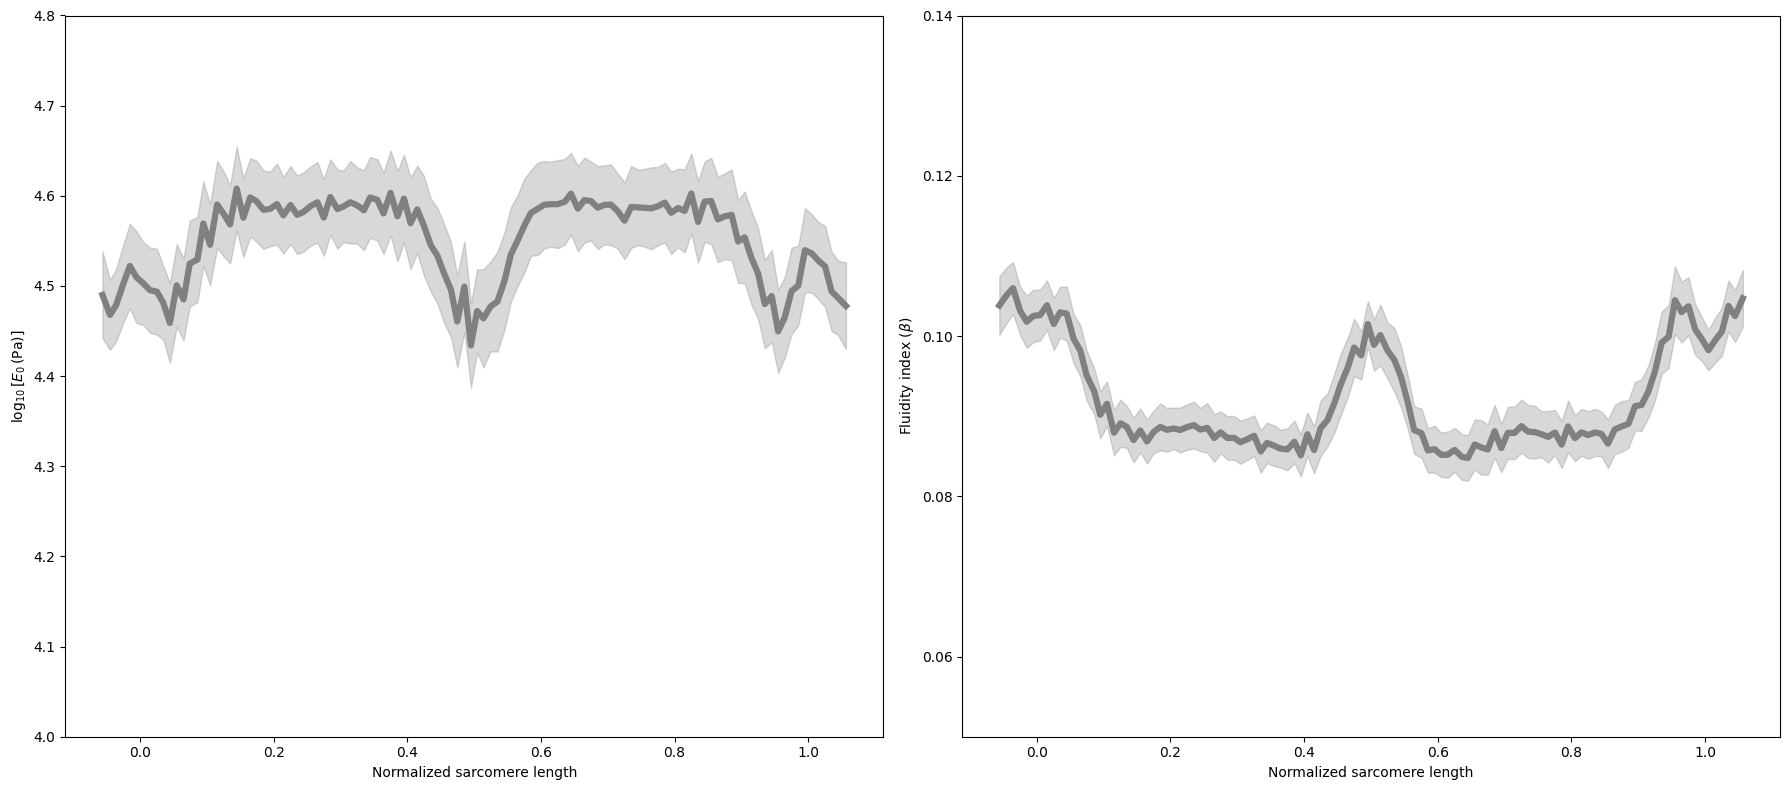

In [6]:
from utils import do_avg_line_profile
from utils import mask_range
df_mech_random = randomize_sacs(df_mech)

   
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8), sharex=True)
do_avg_line_profile(df_mech_random, coi = 'E_0', label='example', ax = axes[0], mask_range = mask_range, bin_percentage = window_size)
do_avg_line_profile(df_mech_random, coi = 'beta', label='example', ax = axes[1], mask_range = mask_range, bin_percentage = window_size)
fig.tight_layout()